# Assessment-Lab-2 - 21.8.26
## Machine Learning Lab - BCSE209P
### Kanad Bhattacharya, 23BCE1265

#### Question

    1. Generate the model to classify the churn using ID3 decision tree, CART and
       Categorical Naive Bayes classifier for the given dataset “churn.csv”. Use
       the following input features - 'Contract', 'PaymentMethod',
       'InternetService', 'OnlineSecurity', 'TechSupport', 'StreamingTV',
       'MonthlyCharges' and target feature as “churn”. Use the split of 70 and 30
       for training and testing the dataset. Compare the performance of the
       models and visualize the results.

    2. Generate the model to classify the documents as hate speech or not hate
       speech using Multinomial Naive Bayes classifier for the given dataset
       “hatespeech”. It has the training, validation and testing data separately.
       Analyze the performance of the data and visualize the results.

    3. Generate the model to classify the subscription of term deposit using
       Multi Layer Perceptron with suitable activation function and Single Layer
       Perceptron for the given dataset “bankmarket.csv”. Use the following input
       features - 'age', 'duration', 'campaign', 'previous', 'housing', 'loan'
       target feature as “y”. Use 70:15:15 (train, validation, test) split and
       analyze the performance of the data and visualize the results. Display
       the validation accuracy and test data accuracy.

### 1.

### ID3, CART & Categorical Naive Bayes - Churn classification

#### Load dataset

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import CategoricalNB, MultinomialNB
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import Perceptron
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [48]:
churn_df = pd.read_csv('Lab 3-24.7.26/churn.csv')
churn_df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


#### Select features

In [49]:
features_churn = ['Contract', 'PaymentMethod', 'InternetService', 'OnlineSecurity',
                  'TechSupport', 'StreamingTV', 'MonthlyCharges']

churn_sub = churn_df[features_churn + ['Churn']].copy()
churn_sub.head()

,Contract,PaymentMethod,InternetService,OnlineSecurity,TechSupport,StreamingTV,MonthlyCharges,Churn
0,Month-to-month,Electronic check,DSL,No,No,No,29.85,No
1,One year,Mailed check,DSL,Yes,No,No,56.95,No
2,Month-to-month,Mailed check,DSL,Yes,No,No,53.85,Yes
3,One year,Bank transfer (automatic),DSL,Yes,Yes,No,42.30,No
4,Month-to-month,Electronic check,Fiber optic,No,No,No,70.70,Yes


#### Train-test split

In [50]:
X_churn_raw = churn_sub[features_churn]
y_churn = churn_sub['Churn']

X_train_raw, X_test_raw, y_train_c, y_test_c = train_test_split(
    X_churn_raw, y_churn, test_size=0.3, random_state=1265, stratify=y_churn
)

#### Preprocessing (fit on training data only)

Both the ordinal encoder used for the tree models and the bin edges / encoder
used for Categorical NB are fit on the training split only, then reused to
transform the test split. Fitting them on the full dataset before splitting
would leak the test rows' categories and quantile distribution into the
"training" preprocessing step, inflating the reported test accuracy.

In [51]:
cat_cols = ['Contract', 'PaymentMethod', 'InternetService', 'OnlineSecurity', 'TechSupport', 'StreamingTV']


X_train_ct = X_train_raw.copy()
X_test_ct = X_test_raw.copy()

encoder_churn = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train_ct[cat_cols] = encoder_churn.fit_transform(X_train_ct[cat_cols])
X_test_ct[cat_cols] = encoder_churn.transform(X_test_ct[cat_cols])


X_train_cn = X_train_raw.copy()
X_test_cn = X_test_raw.copy()

_, bin_edges = pd.qcut(X_train_cn['MonthlyCharges'], q=4, retbins=True)
bin_edges[0], bin_edges[-1] = -np.inf, np.inf
bin_labels = ['Low', 'Medium', 'High', 'Very High']

X_train_cn['MonthlyCharges'] = pd.cut(X_train_cn['MonthlyCharges'], bins=bin_edges, labels=bin_labels)
X_test_cn['MonthlyCharges'] = pd.cut(X_test_cn['MonthlyCharges'], bins=bin_edges, labels=bin_labels)

encoder_churn_nb = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train_cn = encoder_churn_nb.fit_transform(X_train_cn)
X_test_cn = encoder_churn_nb.transform(X_test_cn)

#### Train models

In [52]:
id3_model = DecisionTreeClassifier(criterion='entropy', max_depth=5, random_state=1265)
id3_model.fit(X_train_ct, y_train_c)
y_pred_id3 = id3_model.predict(X_test_ct)

cart_model = DecisionTreeClassifier(criterion='gini', max_depth=5, random_state=1265)
cart_model.fit(X_train_ct, y_train_c)
y_pred_cart = cart_model.predict(X_test_ct)

catnb_model = CategoricalNB()
catnb_model.fit(X_train_cn, y_train_c)
y_pred_catnb = catnb_model.predict(X_test_cn)

#### Performance evaluation

In [53]:
id3_accuracy = accuracy_score(y_test_c, y_pred_id3)
cart_accuracy = accuracy_score(y_test_c, y_pred_cart)
catnb_accuracy = accuracy_score(y_test_c, y_pred_catnb)

print(f"ID3 Accuracy: {id3_accuracy:.4f}")
print(f"CART Accuracy: {cart_accuracy:.4f}")
print(f"Categorical NB Accuracy: {catnb_accuracy:.4f}")

print()

print("ID3 Classification Report:")
print(classification_report(y_test_c, y_pred_id3))

print("CART Classification Report:")
print(classification_report(y_test_c, y_pred_cart))

print("Categorical NB Classification Report:")
print(classification_report(y_test_c, y_pred_catnb))

ID3 Accuracy: 0.7724
CART Accuracy: 0.7724
Categorical NB Accuracy: 0.7269

ID3 Classification Report:
              precision    recall  f1-score   support

          No       0.83      0.87      0.85      1552
         Yes       0.58      0.50      0.54       561

    accuracy                           0.77      2113
   macro avg       0.71      0.69      0.69      2113
weighted avg       0.76      0.77      0.77      2113

CART Classification Report:
              precision    recall  f1-score   support

          No       0.83      0.87      0.85      1552
         Yes       0.58      0.50      0.54       561

    accuracy                           0.77      2113
   macro avg       0.71      0.69      0.69      2113
weighted avg       0.76      0.77      0.77      2113

Categorical NB Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.71      0.79      1552
         Yes       0.49      0.77      0.60       561

    accuracy 

#### Visualize results

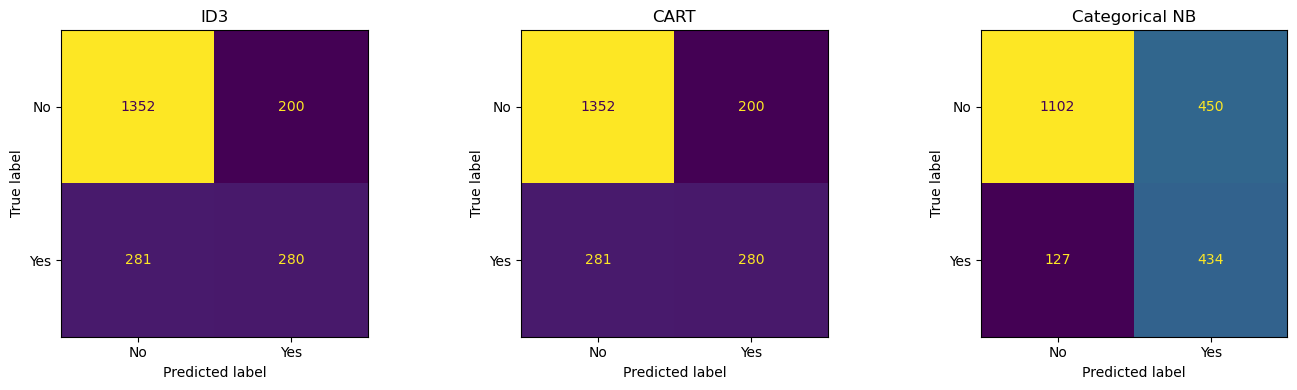

In [54]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, (name, y_pred) in zip(axes, [('ID3', y_pred_id3), ('CART', y_pred_cart), ('Categorical NB', y_pred_catnb)]):
    cm = confusion_matrix(y_test_c, y_pred, labels=id3_model.classes_)
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=id3_model.classes_).plot(ax=ax, colorbar=False)
    ax.set_title(name)

plt.tight_layout()
plt.show()

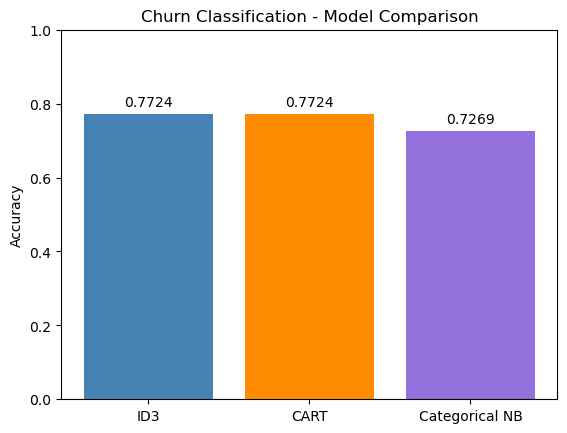

In [55]:
models_churn = ['ID3', 'CART', 'Categorical NB']
accuracies_churn = [id3_accuracy, cart_accuracy, catnb_accuracy]

plt.bar(models_churn, accuracies_churn, color=['steelblue', 'darkorange', 'mediumpurple'])
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.title('Churn Classification - Model Comparison')
for i, acc in enumerate(accuracies_churn):
    plt.text(i, acc + 0.02, f"{acc:.4f}", ha='center')
plt.show()

### 2.

### Multinomial Naive Bayes - Hate speech classification

#### Load dataset

In [56]:
hate_train_df = pd.read_csv('Assessment Lab 2-21.8.26/hatespeech/train.csv')
hate_valid_df = pd.read_csv('Assessment Lab 2-21.8.26/hatespeech/valid.csv')
hate_test_df = pd.read_csv('Assessment Lab 2-21.8.26/hatespeech/test.csv')

print(f"Train shape: {hate_train_df.shape}, Valid shape: {hate_valid_df.shape}, Test shape: {hate_test_df.shape}")
hate_train_df.head()

Train shape: (10000, 2), Valid shape: (4232, 2), Test shape: (4232, 2)


,text,label
0,GASTOS NI VP BINAY SA POLITICAL ADS HALOS P7-M...,0
1,Mar Roxas TANG INA TUWID NA DAAN DAW . . EH SY...,1
2,Salamat sa walang sawang suporta ng mga taga m...,0
3,[MENTION] putangina mo binay TAKBO PA,1
4,"Binay with selective amnesia , forgetting abou...",0


#### Vectorize text

In [57]:
hate_vectorizer = CountVectorizer(max_features=5000, stop_words='english')

X_train_hate = hate_vectorizer.fit_transform(hate_train_df['text'])
X_valid_hate = hate_vectorizer.transform(hate_valid_df['text'])
X_test_hate = hate_vectorizer.transform(hate_test_df['text'])

y_train_hate = hate_train_df['label']
y_valid_hate = hate_valid_df['label']
y_test_hate = hate_test_df['label']

#### Train model

In [58]:
hate_model = MultinomialNB()
hate_model.fit(X_train_hate, y_train_hate)

y_valid_pred_hate = hate_model.predict(X_valid_hate)
y_test_pred_hate = hate_model.predict(X_test_hate)

#### Performance evaluation

In [59]:
hate_valid_accuracy = accuracy_score(y_valid_hate, y_valid_pred_hate)
hate_test_accuracy = accuracy_score(y_test_hate, y_test_pred_hate)

print(f"Validation Accuracy: {hate_valid_accuracy:.4f}")
print(f"Test Accuracy: {hate_test_accuracy:.4f}")

print()

print("Validation Classification Report:")
print(classification_report(y_valid_hate, y_valid_pred_hate))

print("Test Classification Report:")
print(classification_report(y_test_hate, y_test_pred_hate))

Validation Accuracy: 0.7273
Test Accuracy: 0.7250

Validation Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.69      0.73      2299
           1       0.68      0.77      0.72      1933

    accuracy                           0.73      4232
   macro avg       0.73      0.73      0.73      4232
weighted avg       0.73      0.73      0.73      4232

Test Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.70      0.73      2225
           1       0.69      0.75      0.72      2007

    accuracy                           0.72      4232
   macro avg       0.73      0.73      0.72      4232
weighted avg       0.73      0.72      0.73      4232



#### Visualize results

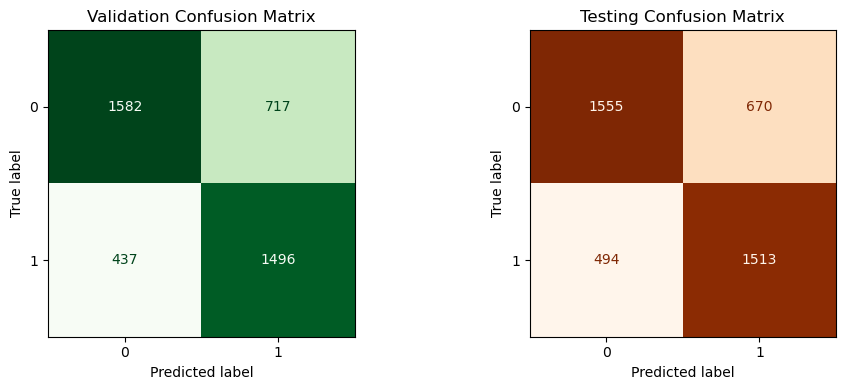

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

cm_valid_hate = confusion_matrix(y_valid_hate, y_valid_pred_hate)
ConfusionMatrixDisplay(confusion_matrix=cm_valid_hate).plot(ax=axes[0], cmap='Greens', colorbar=False)
axes[0].set_title('Validation Confusion Matrix')

cm_test_hate = confusion_matrix(y_test_hate, y_test_pred_hate)
ConfusionMatrixDisplay(confusion_matrix=cm_test_hate).plot(ax=axes[1], cmap='Oranges', colorbar=False)
axes[1].set_title('Testing Confusion Matrix')

plt.tight_layout()
plt.show()

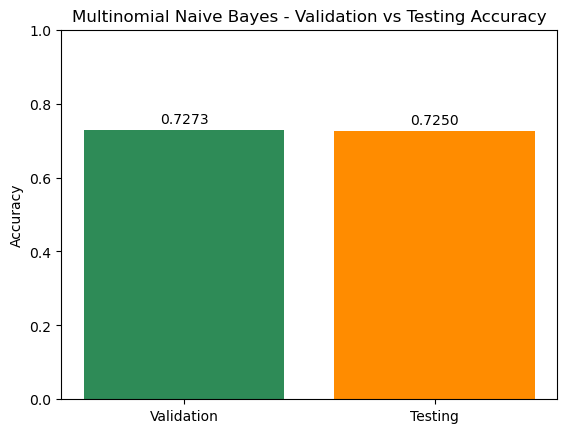

In [61]:
plt.bar(['Validation', 'Testing'], [hate_valid_accuracy, hate_test_accuracy], color=['seagreen', 'darkorange'])
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.title('Multinomial Naive Bayes - Validation vs Testing Accuracy')
for i, acc in enumerate([hate_valid_accuracy, hate_test_accuracy]):
    plt.text(i, acc + 0.02, f"{acc:.4f}", ha='center')
plt.show()

### 3.

### MLP & Single Layer Perceptron - Term deposit subscription

#### Load dataset

In [62]:
bank_df = pd.read_csv('Lab 5-7.8.26/bankmarket.csv', sep=';')
bank_df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


#### Select features

In [63]:
features_bank = ['age', 'duration', 'campaign', 'previous', 'housing', 'loan']

X_bank = bank_df[features_bank].copy()
y_bank = (bank_df['y'] == 'yes').astype(int)

#### Train:validation:test split (70:15:15)

In [64]:
X_train_b, X_temp_b, y_train_b, y_temp_b = train_test_split(
    X_bank, y_bank, test_size=0.3, random_state=1265, stratify=y_bank
)
X_val_b, X_test_b, y_val_b, y_test_b = train_test_split(
    X_temp_b, y_temp_b, test_size=0.5, random_state=1265, stratify=y_temp_b
)

print(f"Train: {len(X_train_b)}, Validation: {len(X_val_b)}, Test: {len(X_test_b)}")

Train: 28831, Validation: 6178, Test: 6179


#### Encode categorical features (fit on training data only)

The ordinal encoder for `housing`/`loan` is fit on `X_train_b` only, then reused
to transform the validation and test splits, avoiding leakage from those splits
into the fitted preprocessing step.

In [65]:
X_train_b = X_train_b.copy()
X_val_b = X_val_b.copy()
X_test_b = X_test_b.copy()

encoder_bank = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train_b[['housing', 'loan']] = encoder_bank.fit_transform(X_train_b[['housing', 'loan']])
X_val_b[['housing', 'loan']] = encoder_bank.transform(X_val_b[['housing', 'loan']])
X_test_b[['housing', 'loan']] = encoder_bank.transform(X_test_b[['housing', 'loan']])

#### Feature scaling

In [66]:
scaler_b = StandardScaler()
X_train_b_scaled = scaler_b.fit_transform(X_train_b)
X_val_b_scaled = scaler_b.transform(X_val_b)
X_test_b_scaled = scaler_b.transform(X_test_b)

#### Train models

In [67]:
mlp_model = MLPClassifier(hidden_layer_sizes=(16, 8), activation='relu',
                           max_iter=500, random_state=1265)
mlp_model.fit(X_train_b_scaled, y_train_b)

y_val_pred_mlp = mlp_model.predict(X_val_b_scaled)
y_test_pred_mlp = mlp_model.predict(X_test_b_scaled)


slp_model = Perceptron(max_iter=1000, random_state=1265)
slp_model.fit(X_train_b_scaled, y_train_b)

y_val_pred_slp = slp_model.predict(X_val_b_scaled)
y_test_pred_slp = slp_model.predict(X_test_b_scaled)

#### Performance evaluation

In [68]:
mlp_val_accuracy = accuracy_score(y_val_b, y_val_pred_mlp)
mlp_test_accuracy = accuracy_score(y_test_b, y_test_pred_mlp)
slp_val_accuracy = accuracy_score(y_val_b, y_val_pred_slp)
slp_test_accuracy = accuracy_score(y_test_b, y_test_pred_slp)

print(f"MLP Validation Accuracy: {mlp_val_accuracy:.4f}")
print(f"MLP Test Accuracy: {mlp_test_accuracy:.4f}")

print()

print(f"SLP Validation Accuracy: {slp_val_accuracy:.4f}")
print(f"SLP Test Accuracy: {slp_test_accuracy:.4f}")

print()

print("MLP Test Classification Report:")
print(classification_report(y_test_b, y_test_pred_mlp))

print("SLP Test Classification Report:")
print(classification_report(y_test_b, y_test_pred_slp))

MLP Validation Accuracy: 0.9006
MLP Test Accuracy: 0.9014

SLP Validation Accuracy: 0.8475
SLP Test Accuracy: 0.8503

MLP Test Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.97      0.95      5483
           1       0.61      0.36      0.45       696

    accuracy                           0.90      6179
   macro avg       0.76      0.66      0.70      6179
weighted avg       0.89      0.90      0.89      6179

SLP Test Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.91      0.92      5483
           1       0.35      0.38      0.36       696

    accuracy                           0.85      6179
   macro avg       0.63      0.64      0.64      6179
weighted avg       0.86      0.85      0.85      6179



#### Visualize results

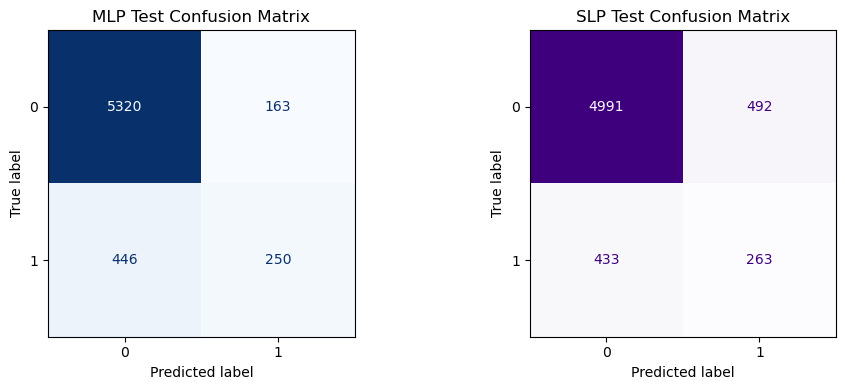

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

cm_mlp = confusion_matrix(y_test_b, y_test_pred_mlp)
ConfusionMatrixDisplay(confusion_matrix=cm_mlp).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('MLP Test Confusion Matrix')

cm_slp = confusion_matrix(y_test_b, y_test_pred_slp)
ConfusionMatrixDisplay(confusion_matrix=cm_slp).plot(ax=axes[1], cmap='Purples', colorbar=False)
axes[1].set_title('SLP Test Confusion Matrix')

plt.tight_layout()
plt.show()

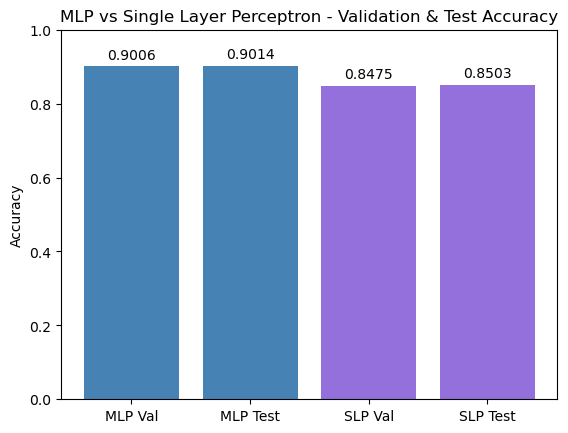

In [70]:
labels_bank = ['MLP Val', 'MLP Test', 'SLP Val', 'SLP Test']
accuracies_bank = [mlp_val_accuracy, mlp_test_accuracy, slp_val_accuracy, slp_test_accuracy]

plt.bar(labels_bank, accuracies_bank, color=['steelblue', 'steelblue', 'mediumpurple', 'mediumpurple'])
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.title('MLP vs Single Layer Perceptron - Validation & Test Accuracy')
for i, acc in enumerate(accuracies_bank):
    plt.text(i, acc + 0.02, f"{acc:.4f}", ha='center')
plt.show()